# 01 · Dataset investigation (Phase 3)

**Goal:** check RAVDESS and CREMA-D *from the actual files*, not from what papers say.

This notebook:
1. Builds a metadata table per corpus (speaker, gender, emotion, harmonised label, sample rate, duration).
2. Runs integrity checks (file counts, unreadable files, sample rates).
3. Shows label, speaker and duration distributions.
4. Creates **speaker-independent folds** and proves no speaker leaks between them.
5. Saves `data/metadata/*.csv` and `results/phase3_dataset_summary.json`.

Run **Kernel → Restart & Run All**. Datasets must be downloaded first (see `data/README.md`).

In [3]:
import sys, json
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from src.data import (build_ravdess_metadata, build_cremad_metadata, add_speaker_folds,
                      check_no_speaker_leakage, save_metadata, HARMONISED, RAW_DIR)

FIG_DIR = PROJECT_ROOT / "results" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 140)

# Chart style: one hue per corpus, light grid, no clutter
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "figure.dpi": 110})
print("Project root:", PROJECT_ROOT)
print("RAVDESS folder exists:", (RAW_DIR / "ravdess").exists())
print("CREMA-D folder exists:", (RAW_DIR / "cremad" / "AudioWAV").exists())

Project root: /Users/yash/Machine learning/lucid-speech-emotion-xai
RAVDESS folder exists: True
CREMA-D folder exists: True


## 1. Build metadata tables
Reads only file headers, so it takes about a minute.

In [4]:
rav = build_ravdess_metadata()
cre = build_cremad_metadata()
print(f"RAVDESS rows: {len(rav)}  (expected 1440)")
print(f"CREMA-D rows: {len(cre)}  (expected 7442)")
rav.head(3)

RAVDESS rows: 1440  (expected 1440)
CREMA-D rows: 7442  (expected 7442)


,path,file,corpus,modality,vocal_channel,emotion,label,intensity,sentence,repetition,speaker_id,gender,sample_rate,channels,duration_s,subtype,read_error
0,data/raw/ravdess/Actor_01/03-01-01-01-01-01-01...,03-01-01-01-01-01-01.wav,ravdess,03,01,neutral,neutral,normal,Kids are talking by the door,1,ravdess_01,male,48000,1,3.3033,PCM_16,
1,data/raw/ravdess/Actor_01/03-01-01-01-01-02-01...,03-01-01-01-01-02-01.wav,ravdess,03,01,neutral,neutral,normal,Kids are talking by the door,2,ravdess_01,male,48000,1,3.3367,PCM_16,
2,data/raw/ravdess/Actor_01/03-01-01-01-02-01-01...,03-01-01-01-02-01-01.wav,ravdess,03,01,neutral,neutral,normal,Dogs are sitting by the door,1,ravdess_01,male,48000,1,3.2699,PCM_16,


In [5]:
cre.head(3)

,path,file,corpus,actor_id,speaker_id,sentence_code,sentence,emotion_code,emotion,label,...,channels,duration_s,subtype,read_error,age,gender,race,ethnicity,voice_vote,voice_agrees
0,data/raw/cremad/AudioWAV/1001_DFA_ANG_XX.wav,1001_DFA_ANG_XX.wav,cremad,1001,cremad_1001,DFA,Don't forget a jacket,ANG,angry,angry,...,1,2.2756,PCM_16,,51,male,Caucasian,Not Hispanic,A,True
1,data/raw/cremad/AudioWAV/1001_DFA_DIS_XX.wav,1001_DFA_DIS_XX.wav,cremad,1001,cremad_1001,DFA,Don't forget a jacket,DIS,disgust,disgust,...,1,2.3357,PCM_16,,51,male,Caucasian,Not Hispanic,D,True
2,data/raw/cremad/AudioWAV/1001_DFA_FEA_XX.wav,1001_DFA_FEA_XX.wav,cremad,1001,cremad_1001,DFA,Don't forget a jacket,FEA,fearful,fearful,...,1,2.1688,PCM_16,,51,male,Caucasian,Not Hispanic,F,True


## 2. Integrity checks

In [6]:
for name, df in [("RAVDESS", rav), ("CREMA-D", cre)]:
    bad = df[df["read_error"] != ""]
    print(f"--- {name} ---")
    print("Unreadable files:", len(bad))
    if len(bad):
        print(bad[["file", "read_error"]].head(10).to_string(index=False))
    ok = df[df["read_error"] == ""]
    print("Sample rates:", ok["sample_rate"].value_counts().to_dict())
    print("Channels:    ", ok["channels"].value_counts().to_dict())
    print("Bit depth:   ", ok["subtype"].value_counts().to_dict())
    print("Duplicate files:", df["file"].duplicated().sum())
    print("Duration (s):", ok["duration_s"].describe().round(2).to_dict())
    print("Clips shorter than 1 s:", (ok["duration_s"] < 1.0).sum(), "\n")

--- RAVDESS ---
Unreadable files: 0
Sample rates: {48000: 1440}
Channels:     {1: 1435, 2: 5}
Bit depth:    {'PCM_16': 1440}
Duplicate files: 0
Duration (s): {'count': 1440.0, 'mean': 3.7, 'std': 0.34, 'min': 2.94, '25%': 3.47, '50%': 3.67, '75%': 3.87, 'max': 5.27}
Clips shorter than 1 s: 0 

--- CREMA-D ---
Unreadable files: 0
Sample rates: {16000: 7442}
Channels:     {1: 7442}
Bit depth:    {'PCM_16': 7442}
Duplicate files: 0
Duration (s): {'count': 7442.0, 'mean': 2.54, 'std': 0.51, 'min': 1.27, '25%': 2.2, '50%': 2.5, '75%': 2.84, 'max': 5.0}
Clips shorter than 1 s: 0 



**What to look for**
- *Unreadable files* = 0 ideally. `git-lfs pointer` means CREMA-D audio was not actually downloaded.
- *Sample rates*: we expect RAVDESS 48 kHz and CREMA-D 16 kHz. Both get resampled to **16 kHz** in Phase 5.
- *Very short clips* may be broken recordings and are worth listening to.

## 3. Emotion labels and harmonisation

In [7]:
mapping = pd.DataFrame({"harmonised_label": HARMONISED})
mapping["RAVDESS clips"] = mapping["harmonised_label"].map(rav["label"].value_counts()).fillna(0).astype(int)
mapping["CREMA-D clips"] = mapping["harmonised_label"].map(cre["label"].value_counts()).fillna(0).astype(int)
print("RAVDESS emotions dropped for cross-corpus work:",
      rav.loc[rav["label"].isna(), "emotion"].value_counts().to_dict())
mapping

RAVDESS emotions dropped for cross-corpus work: {'calm': 192, 'surprised': 192}


,harmonised_label,RAVDESS clips,CREMA-D clips
0,neutral,96,1087
1,happy,192,1271
2,sad,192,1271
3,angry,192,1271
4,fearful,192,1271
5,disgust,192,1271


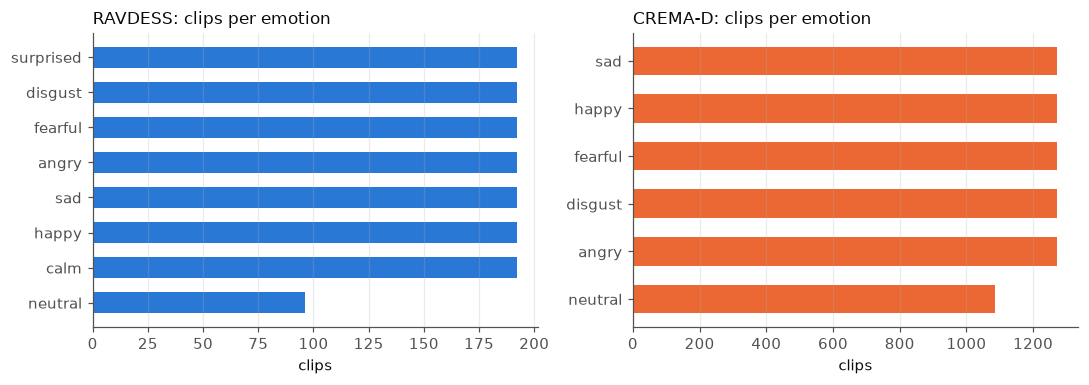

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=False)
for ax, df, name, colour in [(axes[0], rav, "RAVDESS", BLUE), (axes[1], cre, "CREMA-D", ORANGE)]:
    counts = df["emotion"].value_counts().sort_values()
    ax.barh(counts.index, counts.values, color=colour, height=0.6)
    ax.set_title(f"{name}: clips per emotion", loc="left", color=INK, fontsize=11)
    ax.set_xlabel("clips")
    ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "p3_emotion_counts.png", bbox_inches="tight")
plt.show()

**Notice:** RAVDESS *neutral* has half as many clips as the other emotions, because neutral has no "strong" intensity.
This class imbalance is one reason **UAR (macro recall)** is our main metric.

## 4. Speakers and demographics

In [9]:
for name, df in [("RAVDESS", rav), ("CREMA-D", cre)]:
    per_spk = df.groupby("speaker_id").size()
    print(f"{name}: {df['speaker_id'].nunique()} speakers, clips per speaker min={per_spk.min()} "
          f"median={per_spk.median():.0f} max={per_spk.max()}")
    print("  gender (speakers):", df.drop_duplicates("speaker_id")["gender"].value_counts().to_dict())
if "age" in cre:
    spk = cre.drop_duplicates("speaker_id")
    print("CREMA-D age:", spk["age"].describe().round(1).to_dict())
    print("CREMA-D race:", spk["race"].value_counts().to_dict())

RAVDESS: 24 speakers, clips per speaker min=60 median=60 max=60
  gender (speakers): {'male': 12, 'female': 12}
CREMA-D: 91 speakers, clips per speaker min=76 median=82 max=82
  gender (speakers): {'male': 48, 'female': 43}
CREMA-D age: {'count': 91.0, 'mean': 36.4, 'std': 13.3, 'min': 20.0, '25%': 25.0, '50%': 33.0, '75%': 45.5, 'max': 74.0}
CREMA-D race: {'Caucasian': 61, 'African American': 22, 'Asian': 7, 'Unknown': 1}


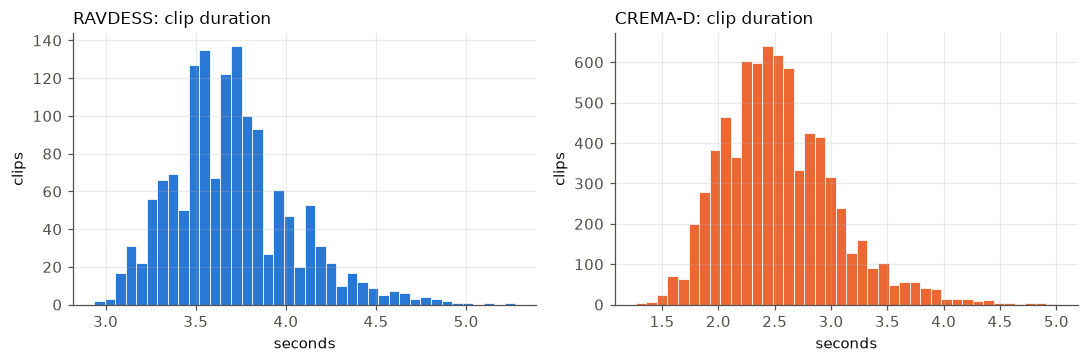

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, df, name, colour in [(axes[0], rav, "RAVDESS", BLUE), (axes[1], cre, "CREMA-D", ORANGE)]:
    ok = df[df["read_error"] == ""]
    ax.hist(ok["duration_s"], bins=40, color=colour, edgecolor="white", linewidth=0.5)
    ax.set_title(f"{name}: clip duration", loc="left", color=INK, fontsize=11)
    ax.set_xlabel("seconds"); ax.set_ylabel("clips")
fig.tight_layout()
fig.savefig(FIG_DIR / "p3_durations.png", bbox_inches="tight")
plt.show()

## 5. CREMA-D rater agreement (label quality)

In [11]:
if "voice_agrees" in cre:
    rated = cre[cre["voice_vote"].notna()]
    print(f"Clips with an audio-only vote: {len(rated)}")
    print(f"Majority vote = intended emotion: {rated['voice_agrees'].mean():.1%}")
    print(rated.groupby("label")["voice_agrees"].mean().round(3).sort_values().to_string())
    print("\nExample vote values:", rated["voice_vote"].value_counts().head(8).to_dict())
else:
    print("summaryTable.csv not found - agreement check skipped")

Clips with an audio-only vote: 7442
Majority vote = intended emotion: 41.6%
label
sad        0.164
happy      0.260
disgust    0.270
fearful    0.320
angry      0.606
neutral    0.957

Example vote values: {'N': 3897, 'A': 986, 'F': 645, 'D': 547, 'S': 370, 'H': 353, 'N:S': 114, 'F:N': 93}


This is the basis for our **robustness check**: we train on intended labels, then repeat key experiments on clips
where listeners agreed with the intended emotion.
⚠️ Check the *example vote values* printed above. If they are not single letters (A, D, F, H, N, S), tell us so the
agreement rule can be adjusted.

## 6. Speaker-independent folds
Every clip of a speaker goes into the same fold, so no voice appears in both training and test data.

In [12]:
rav = add_speaker_folds(rav, n_splits=5, seed=42)
cre = add_speaker_folds(cre, n_splits=5, seed=42)
for name, df in [("RAVDESS", rav), ("CREMA-D", cre)]:
    print(f"{name}: no speaker leakage = {check_no_speaker_leakage(df)}")
    used = df[df["fold"] >= 0]
    table = pd.crosstab(used["fold"], used["label"])
    table["speakers"] = used.groupby("fold")["speaker_id"].nunique()
    print(table, "\n")

RAVDESS: no speaker leakage = True
label  angry  disgust  fearful  happy  neutral  sad  speakers
fold                                                         
0         40       40       40     40       20   40         5
1         40       40       40     40       20   40         5
2         40       40       40     40       20   40         5
3         40       40       40     40       20   40         5
4         32       32       32     32       16   32         4 

CREMA-D: no speaker leakage = True
label  angry  disgust  fearful  happy  neutral  sad  speakers
fold                                                         
0        251      251      251    251      214  251        18
1        252      252      252    252      215  252        18
2        252      252      252    252      216  252        18
3        264      264      264    264      226  264        19
4        252      252      252    252      216  252        18 



## 7. Save metadata and summary

In [13]:
p1 = save_metadata(rav, "ravdess")
p2 = save_metadata(cre, "cremad")

def summary(df):
    ok = df[df["read_error"] == ""]
    return {
        "files": int(len(df)),
        "unreadable": int((df["read_error"] != "").sum()),
        "speakers": int(df["speaker_id"].nunique()),
        "sample_rates": {str(k): int(v) for k, v in ok["sample_rate"].value_counts().items()},
        "channels": {str(k): int(v) for k, v in ok["channels"].value_counts().items()},
        "duration_s": {k: round(float(v), 3) for k, v in ok["duration_s"].describe().items()},
        "emotion_counts": {k: int(v) for k, v in df["emotion"].value_counts().items()},
        "harmonised_counts": {k: int(v) for k, v in df["label"].value_counts().items()},
        "speaker_gender": {str(k): int(v) for k, v in df.drop_duplicates("speaker_id")["gender"].value_counts().items()},
        "no_speaker_leakage": check_no_speaker_leakage(df),
    }

result = {"ravdess": summary(rav), "cremad": summary(cre)}
if "voice_agrees" in cre:
    rated = cre[cre["voice_vote"].notna()]
    result["cremad"]["voice_agreement_rate"] = round(float(rated["voice_agrees"].mean()), 4)
    result["cremad"]["voice_agreement_by_label"] = rated.groupby("label")["voice_agrees"].mean().round(4).to_dict()

out = PROJECT_ROOT / "results" / "phase3_dataset_summary.json"
out.write_text(json.dumps(result, indent=2))
print("Saved:", p1.name, p2.name, out.name)

Saved: ravdess.csv cremad.csv phase3_dataset_summary.json
